# Predicting [Airline Satisfaction](https://www.kaggle.com/competitions/playground-series-s6e10/data)
## Exploring Data Analysis and Feature Engineering

In [46]:
import pandas as pd
import numpy as np

In [47]:
train_path = '../data/train.csv'
test_path = '../data/test.csv'

df_train = pd.read_csv(train_path)

In [55]:
df_train.drop_duplicates()

display(df_train.head(20))
display(df_train.info())
display(df_train.describe())
display(f'Train dataset size {df_train.shape}')

print(f'Features amount: {df_train.shape[1]}')

,Age,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,Inflight entertainment,...,Baggage handling,Checkin service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,Gender,Customer Type,Type of Travel,Class,satisfaction
0,36,694,4,4,4,3,1,4,1,1,...,4,3,1,0,0.0,Female,Loyal Customer,Personal Travel,Eco,0
1,56,651,5,5,5,5,5,4,4,5,...,5,4,3,0,0.0,Male,Loyal Customer,Business travel,Business,1
2,31,1371,3,4,2,5,3,3,3,3,...,4,5,3,0,0.0,Female,Loyal Customer,Personal Travel,Eco,0
3,10,1616,3,5,3,3,3,3,3,3,...,3,4,3,0,0.0,Male,Loyal Customer,Personal Travel,Eco,0
4,23,481,3,4,3,4,5,3,5,5,...,5,3,5,5,0.0,Female,disloyal Customer,Business travel,Eco,0
5,34,584,4,4,4,4,1,4,1,1,...,4,4,1,0,0.0,Female,disloyal Customer,Business travel,Business,0
6,36,1763,5,5,5,5,3,4,4,3,...,4,3,3,0,0.0,Female,Loyal Customer,Business travel,Business,1
7,57,861,1,3,1,3,4,4,4,5,...,5,4,2,0,0.0,Female,Loyal Customer,Personal Travel,Eco,0
8,60,581,3,3,3,3,5,4,5,4,...,4,4,5,0,0.0,Female,Loyal Customer,Business travel,Business,1
9,44,588,3,3,2,2,2,3,2,2,...,4,1,2,0,0.0,Female,disloyal Customer,Business travel,Eco,0


<class 'pandas.DataFrame'>
RangeIndex: 699635 entries, 0 to 699634
Data columns (total 22 columns):
 #   Column                             Non-Null Count   Dtype  
---  ------                             --------------   -----  
 0   Age                                699635 non-null  int64  
 1   Flight Distance                    699635 non-null  int64  
 2   Inflight wifi service              699635 non-null  int64  
 3   Departure/Arrival time convenient  699635 non-null  int64  
 4   Ease of Online booking             699635 non-null  int64  
 5   Gate location                      699635 non-null  int64  
 6   Food and drink                     699635 non-null  int64  
 7   Online boarding                    699635 non-null  int64  
 8   Seat comfort                       699635 non-null  int64  
 9   Inflight entertainment             699635 non-null  int64  
 10  On-board service                   699635 non-null  int64  
 11  Leg room service                   699635 non-null

None

,Age,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,satisfaction
count,699635.000000,699635.000000,699635.000000,699635.00000,699635.00000,699635.000000,699635.000000,699635.000000,699635.000000,699635.000000,699635.000000,699635.000000,699635.000000,699635.000000,699635.000000,699635.000000,699343.000000,699635.000000
mean,39.001928,1353.778702,2.778722,3.15621,2.81324,3.013734,3.265644,3.364156,3.568950,3.453910,3.517404,3.472847,3.805443,3.420291,3.380401,1.176209,1.134280,0.443573
std,13.800943,954.422566,1.280419,1.47539,1.32955,1.254014,1.300202,1.288538,1.275333,1.308157,1.238474,1.271755,1.079175,1.210604,1.277870,5.982187,5.749304,0.496806
min,7.000000,67.000000,0.000000,0.00000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,27.000000,631.000000,2.000000,2.00000,2.00000,2.000000,2.000000,2.000000,3.000000,2.000000,3.000000,2.000000,3.000000,3.000000,2.000000,0.000000,0.000000,0.000000
50%,40.000000,954.000000,3.000000,3.00000,3.00000,3.000000,3.000000,4.000000,4.000000,4.000000,4.000000,4.000000,4.000000,4.000000,4.000000,0.000000,0.000000,0.000000
75%,50.000000,1814.000000,4.000000,4.00000,4.00000,4.000000,4.000000,4.000000,5.000000,5.000000,4.000000,5.000000,5.000000,4.000000,4.000000,0.000000,0.000000,1.000000
max,85.000000,4983.000000,5.000000,5.00000,5.00000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,489.000000,491.000000,1.000000


'Train dataset size (699635, 22)'

Features amount: 22


In [49]:
TARGET = 'satisfaction'
df_train = df_train.drop(columns=['id'])
df_train[TARGET] = df_train[TARGET].astype(int)
cat_cols = df_train.select_dtypes(str).columns.to_list()
num_cols = df_train.select_dtypes([float, int]).columns.to_list()

print(f'Categorial features: {cat_cols}')
print(f'Numeric features: {num_cols}')

print(len(cat_cols) + len(num_cols))

Categorial features: ['Gender', 'Customer Type', 'Type of Travel', 'Class']
Numeric features: ['Age', 'Flight Distance', 'Inflight wifi service', 'Departure/Arrival time convenient', 'Ease of Online booking', 'Gate location', 'Food and drink', 'Online boarding', 'Seat comfort', 'Inflight entertainment', 'On-board service', 'Leg room service', 'Baggage handling', 'Checkin service', 'Cleanliness', 'Departure Delay in Minutes', 'Arrival Delay in Minutes', 'satisfaction']
22


### Categorial features analysis

In [50]:
import matplotlib.pyplot as plt
import seaborn as sns

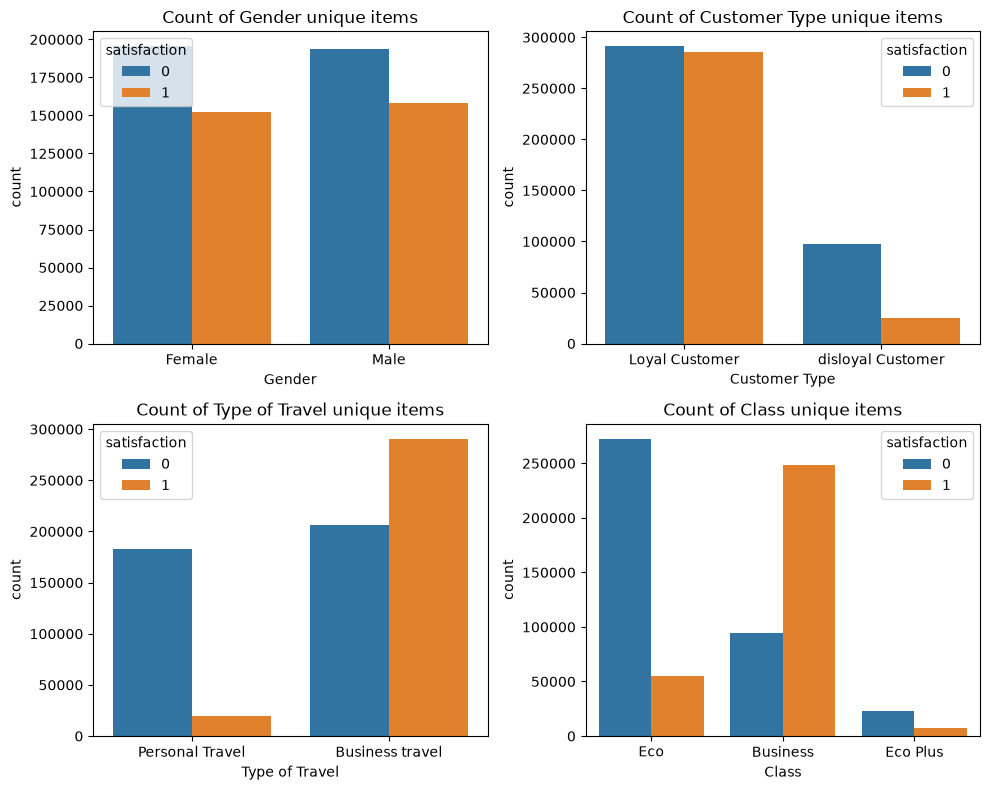

In [51]:
fig, axes = plt.subplots(2, 2, figsize=(10, 8))

for col, ax in zip(cat_cols, axes.ravel()):
    sns.countplot(data=df_train, x=col, ax=ax, hue=TARGET)
    ax.set_title(f'Count of {col} unique items')
plt.tight_layout()

### Numeric features exploring

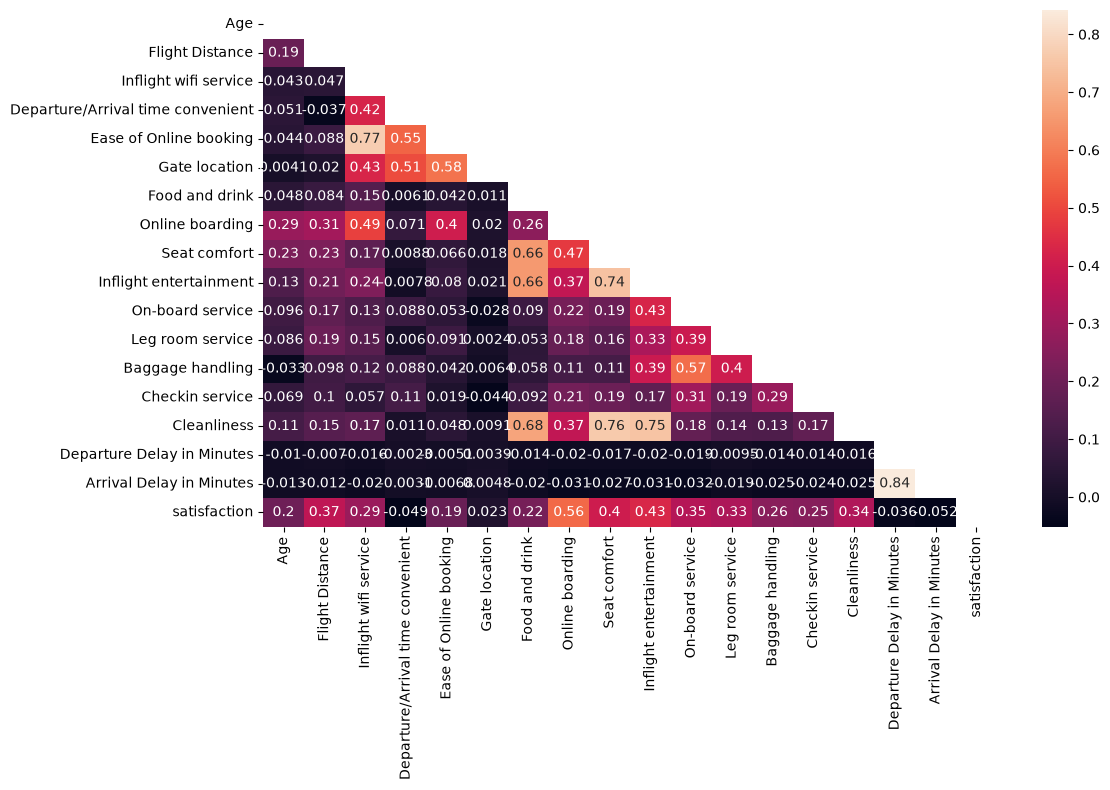

In [52]:
corr = df_train[num_cols].corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
plt.figure(figsize=(12, 8))
sns.heatmap(data=corr, mask=mask,annot=True)
plt.tight_layout()

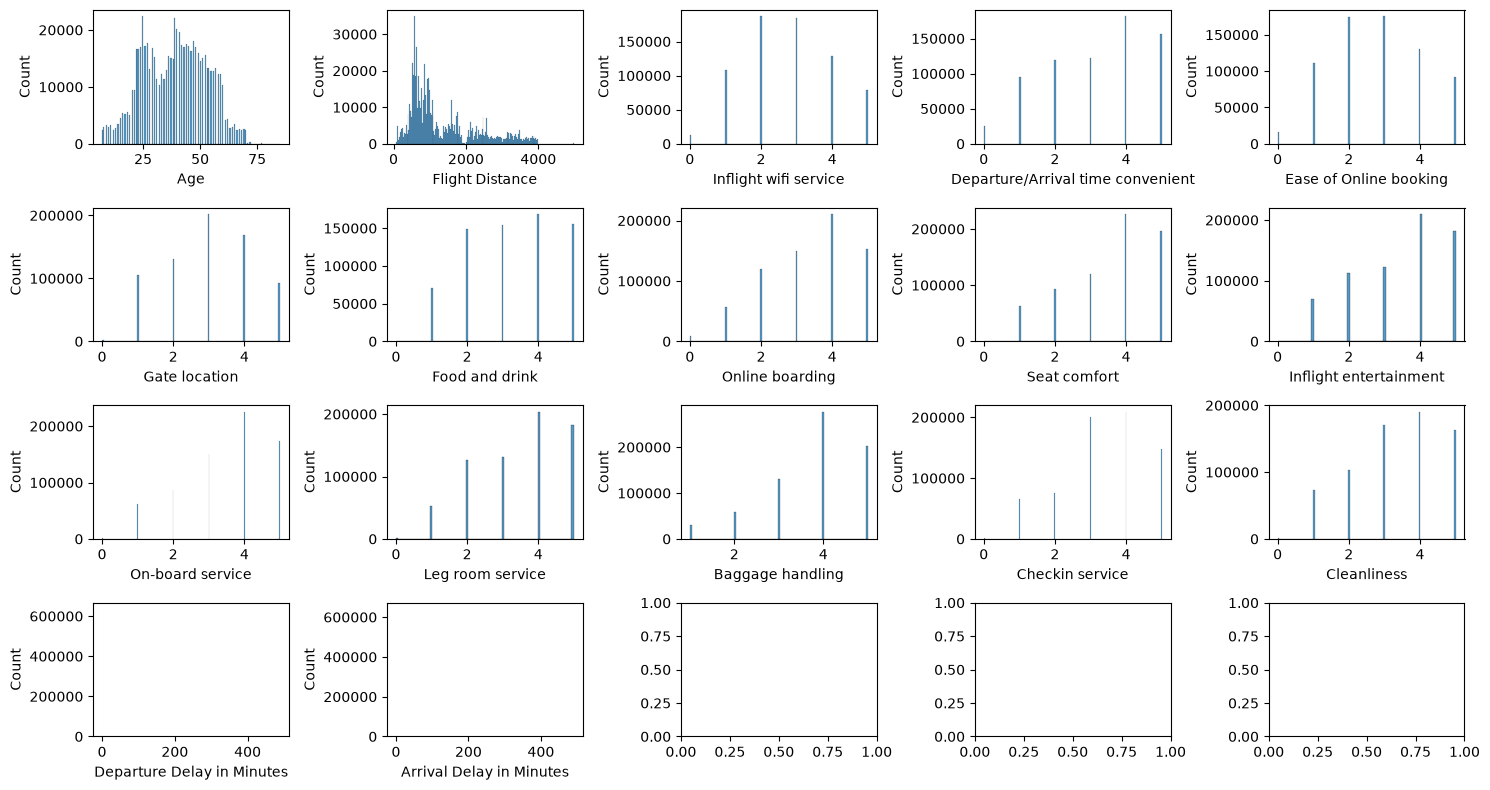

In [53]:
num_cols.remove('satisfaction')
fig, axes = plt.subplots(4, 5, figsize=(15, 8))
for col, ax in zip(num_cols, axes.ravel()):
    sns.histplot(data=df_train, x=col, ax=ax)
plt.tight_layout()

### Gaps Checking

In [54]:
df_train.isna().sum().sort_values(ascending=False)

Arrival Delay in Minutes             292
Age                                    0
Flight Distance                        0
Class                                  0
Type of Travel                         0
Customer Type                          0
Gender                                 0
Departure Delay in Minutes             0
Cleanliness                            0
Checkin service                        0
Baggage handling                       0
Leg room service                       0
On-board service                       0
Inflight entertainment                 0
Seat comfort                           0
Online boarding                        0
Food and drink                         0
Gate location                          0
Ease of Online booking                 0
Departure/Arrival time convenient      0
Inflight wifi service                  0
satisfaction                           0
dtype: int64

### Target analysis

<Axes: xlabel='satisfaction', ylabel='count'>

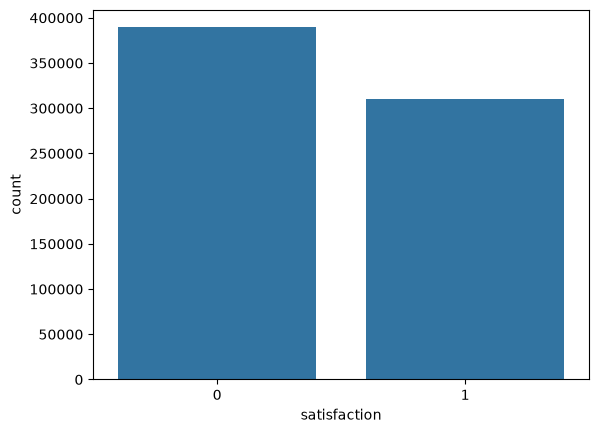

In [63]:
sns.countplot(data=df_train, x=TARGET)

In [70]:
df_train = df_train.drop(columns=['Arrival Delay in Minutes']) 

## Model Training
### Baseline Model Training

In [150]:
from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score, roc_curve, f1_score

In [90]:
X = df_train.drop(columns=[TARGET])
X_enc = pd.get_dummies(X, drop_first=True)
y = df_train[TARGET]

X_train, X_val, y_train, y_val = train_test_split(X_enc, y, shuffle=True, random_state=42, test_size=0.2)

In [112]:
pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('clf', LogisticRegression(max_iter=1000))
])

pipe.fit(X_train, y_train)
bsln_preds_train = pipe.predict_proba(X_train)[:, 1]
bsln_preds_val = pipe.predict_proba(X_val)[:, 1]

bsln_preds_train

array([0.11746858, 0.87012365, 0.10024712, ..., 0.87985646, 0.05870939,
       0.90476451], shape=(559708,))

In [113]:
print(f'Train ROC-AUC: {roc_auc_score(y_train, bsln_preds_train)}')
print(f'Test ROC-AUC: {roc_auc_score(y_val, bsln_preds_val)}')

Train ROC-AUC: 0.9214746395337625
Test ROC-AUC: 0.9212755257112271


## Random Forest training

In [ ]:
from sklearn.ensemble import RandomForestClassifier

In [ ]:
rf_model = RandomForestClassifier(n_estimators=500, min_samples_leaf=3, n_jobs=-1)

rf_param_grid = {
    'max_depth' : [None, 15, 30],
    'min_samples_leaf' : [1, 3, 5, 7]
}

rf_grid = RandomizedSearchCV(rf_model, rf_param_grid, n_iter=5, random_state=42, cv=5, n_jobs=-1)

In [102]:
rf_model.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",500
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric

In [ ]:
rf_preds_train = rf_model.predict_proba(X_train)[:, 1]
rf_preds_val = rf_model.predict_proba(X_val)[:, 1]

In [115]:

print(roc_auc_score(y_train, rf_preds_train))
print(roc_auc_score(y_val, rf_preds_val))


1.0
0.9549205360657376


In [146]:
from xgboost import XGBClassifier
from scipy.stats import randint, uniform

In [147]:
xgb_model = XGBClassifier(n_jobs=1, eval_metric='logloss')

xgb_param_grid = {
    'n_estimators' : randint(300, 900),
    'learning_rate' : uniform(0.01, 0.04),
    'max_depth' : randint(3, 9),
    'subsample' : uniform(0.8, 0.1),
    'colsample_bytree' : uniform(0.7, 0.1),
    'gamma' : uniform(0, 4),
    'reg_lambda' : uniform(1, 5)
}

xgb_grid = RandomizedSearchCV(xgb_model, xgb_param_grid, cv=3, random_state=42, n_jobs=-1, n_iter=30,  scoring='roc_auc')

In [148]:
xgb_grid.fit(X_train, y_train)

,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","XGBClassifier...ree=None, ...)"
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'colsample_bytree': <scipy.stats....t 0x11dbb3a10>, 'gamma': <scipy.stats....t 0x11dbb3c50>, 'learning_rate': <scipy.stats....t 0x11dbb3b90>, 'max_depth': <scipy.stats....t 0x11dbb3890>, ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",30
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'roc_auc'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",3
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``pr

In [158]:
xgb_preds_proba_train = xgb_grid.predict_proba(X_train)[:, 1]
xgb_preds_proba_val = xgb_grid.predict_proba(X_val)[:, 1]

In [159]:
thresholds = np.arange(0.0, 1.01, 0.01)
f1_scores = [f1_score(y_train, xgb_preds_proba_train > t) for t in thresholds]
threshold = thresholds[np.argmax(f1_scores)]


In [162]:
xgb_preds_train = xgb_preds_proba_train > threshold
xgb_preds_val = xgb_preds_proba_val > threshold
print(roc_auc_score(y_train, xgb_preds_proba_train))
print(roc_auc_score(y_val, xgb_preds_proba_val))

0.9651809153477956
0.9582659559381936


In [164]:
df_test = pd.read_csv(test_path)
df_test.isna().sum().sort_values(ascending=False)

Arrival Delay in Minutes             130
id                                     0
Age                                    0
Type of Travel                         0
Customer Type                          0
Gender                                 0
Departure Delay in Minutes             0
Cleanliness                            0
Checkin service                        0
Baggage handling                       0
Leg room service                       0
On-board service                       0
Inflight entertainment                 0
Seat comfort                           0
Online boarding                        0
Food and drink                         0
Gate location                          0
Ease of Online booking                 0
Departure/Arrival time convenient      0
Inflight wifi service                  0
Flight Distance                        0
Class                                  0
dtype: int64

In [165]:
id_col = df_test['id']
df_test = df_test.drop(columns=['id', 'Arrival Delay in Minutes'])
df_test = pd.get_dummies(df_test, drop_first=True)

In [170]:
test_preds_proba  = xgb_grid.predict_proba(df_test)[:, 1]
test_preds = test_preds_proba > threshold
df = pd.DataFrame({
    'id': id_col,
    'satisfaction' : test_preds.astype(int)
})

df.to_csv('../data/submission.csv', index=False)